# Student Exam Performance Predictor

Assignment 1

This project explores the relationship between study hours and exam scores for the Academic Support Office. It uses the 13 observations supplied in the assignment to build and evaluate a simple Linear Regression prototype, then considers when its predictions are useful and when they should not be trusted.

Run the cells in order in a Python 3 notebook with NumPy, Pandas, Matplotlib and scikit-learn installed. The data is included below, so no external data file is needed.


## 1. Project definition and SDLC plan

### Project requirements

The Academic Support Office needs a prototype that investigates whether students who study for more hours tend to achieve higher exam scores. The input is the supplied dataset of paired study hours and exam scores, with study hours used as the model's only predictor. The prototype should produce descriptive statistics, a structured data table, labelled plots, and a Linear Regression model evaluated on held-out observations. It should estimate a score for 7.5 study hours and explain why predictions far outside the observed range should not be trusted.

### SDLC plan

| Stage | Application to this project |
|---|---|
| Requirements | Use the supplied observations to investigate the study-hours relationship, estimate exam scores, and communicate prediction error and limitations. |
| Design | Store the data in NumPy arrays, build a Pandas table, inspect statistics, draw a scatter plot, split the data, fit a model, evaluate it, and write a recommendation. |
| Implementation | Use NumPy for statistics and Boolean comparisons, Pandas for inspection and filtering, Matplotlib for plots, and scikit-learn for splitting, regression and MAE. |
| Testing | Check that the arrays match the provided data, reconcile NumPy and Pandas statistics, confirm input shapes and separate training/test rows, inspect predictions and MAE, and restart the kernel and run all cells. |
| Improvement | Collect a larger, more representative dataset and additional predictors such as attendance, prior grades, sleep and course difficulty; evaluate the revised model on new students. |

### Project flow

Problem definition → supplied data → NumPy statistics → Pandas inspection → scatter plot → train/test split → Linear Regression → predictions and MAE → practical recommendation


## 2. Numerical data setup and basic statistics

### Create the numerical arrays

Each position in the two arrays describes the same student observation. I keep all 13 supplied pairs unchanged and check that both arrays have the same number of values.


In [1]:
import numpy as np

study_hours = np.array([1.0, 2.0, 2.5, 3.0, 4.0, 4.5, 5.0,
                        6.0, 6.5, 7.0, 8.0, 9.0, 10.0])
exam_scores = np.array([42, 48, 51, 55, 62, 65, 69,
                        75, 78, 82, 87, 91, 95])

print("StudyHours observations:", study_hours.size)
print("ExamScore observations:", exam_scores.size)
print("Array lengths match:", study_hours.size == exam_scores.size)


StudyHours observations: 13
ExamScore observations: 13
Array lengths match: True


Both arrays contain 13 observations, so every study-hour value has a corresponding exam score.


### Numerical profile

All summary values below are calculated from the arrays. The first standard deviation describes the complete supplied set using NumPy's default population calculation (`ddof=0`).


In [2]:
mean_study_hours = np.mean(study_hours)
mean_exam_score = np.mean(exam_scores)
score_std = np.std(exam_scores)

print("Number of observations:", exam_scores.size)
print(f"Average study hours: {mean_study_hours:.2f} hours")
print(f"Average exam score: {mean_exam_score:.2f} points")
print(f"Minimum exam score: {np.min(exam_scores)} points")
print(f"Maximum exam score: {np.max(exam_scores)} points")
print(f"Standard deviation of exam scores (ddof=0): {score_std:.2f} points")


Number of observations: 13
Average study hours: 5.27 hours
Average exam score: 69.23 points
Minimum exam score: 42 points
Maximum exam score: 95 points
Standard deviation of exam scores (ddof=0): 16.47 points


The average study time is about 5.27 hours and the average score is about 69.23 points. Scores range from 42 to 95 points, with a population standard deviation of about 16.47 points, showing substantial variation within this small dataset.


### Identify above-average performers


In [3]:
# Compare every score with the mean in one vectorized operation.
above_average_mask = exam_scores > np.mean(exam_scores)
above_average_count = np.sum(above_average_mask)

print("Above-average Boolean mask:", above_average_mask)
print("Number of students scoring above the mean:", above_average_count)


Above-average Boolean mask: [False False False False False False False  True  True  True  True  True
  True]
Number of students scoring above the mean: 6


The expression `exam_scores > np.mean(exam_scores)` compares each score with the overall mean and returns a Boolean array in the same order as the original data. A `True` means that observation is strictly above the mean; a `False` means it is not. Summing the Boolean array counts each `True` as 1 and each `False` as 0, giving **6 above-average students** without manually counting rows.

Overall, these 13 observations cover a broad score range of 42–95 points, with six scores above the mean of about 69.23 points; this summary provides context for the relationship explored next.


## 3. Structured dataset and data inspection

### Build the DataFrame and inspect its first rows

I reuse the arrays from Stage 2 to create a labelled table. `df.head()` shows the first five observations and helps check the column names and the pairing of hours with scores.


In [4]:
import pandas as pd

df = pd.DataFrame({"StudyHours": study_hours, "ExamScore": exam_scores})
df.head()


,StudyHours,ExamScore
0,1.0,42
1,2.0,48
2,2.5,51
3,3.0,55
4,4.0,62


The first five rows match the start of the supplied dataset, from 1 study hour and 42 points to 4 study hours and 62 points.


### Inspect the table dimensions


In [5]:
print("DataFrame shape (rows, columns):", df.shape)


DataFrame shape (rows, columns): (13, 2)


`df.shape` is `(13, 2)`: there are 13 observations and two original columns. It reports table dimensions rather than the values in the table.


### Inspect the numerical summary


In [6]:
df.describe()


,StudyHours,ExamScore
count,13.000000,13.000000
mean,5.269231,69.230769
std,2.781002,17.137453
min,1.000000,42.000000
25%,3.000000,55.000000
50%,5.000000,69.000000
75%,7.000000,82.000000
max,10.000000,95.000000


`df.describe()` reports the count, mean, standard deviation, minimum, quartiles and maximum of each numerical column. The count, means and score extremes agree with Stage 2; the median exam score is 69 points. Its score standard deviation is about 17.14 because Pandas uses the sample formula (`ddof=1`), whereas the earlier NumPy calculation used the population formula (`ddof=0`).


In [7]:
print(f"NumPy sample score standard deviation (ddof=1): {np.std(exam_scores, ddof=1):.2f}")
print(f"Pandas sample score standard deviation: {df['ExamScore'].std():.2f}")


NumPy sample score standard deviation (ddof=1): 17.14
Pandas sample score standard deviation: 17.14


With the same `ddof=1` setting, both libraries give 17.14 points. The sample formula divides the sum of squared deviations by 12 rather than 13, so this difference is expected, not a data mismatch.


### Add the AboveAverage column


In [8]:
df["AboveAverage"] = df["ExamScore"] > df["ExamScore"].mean()
df


,StudyHours,ExamScore,AboveAverage
0,1.0,42,False
1,2.0,48,False
2,2.5,51,False
3,3.0,55,False
4,4.0,62,False
5,4.5,65,False
6,5.0,69,False
7,6.0,75,True
8,6.5,78,True
9,7.0,82,True


The new column is calculated from the scores and contains Boolean values. It marks the same six observations as the NumPy comparison; the dataset now has three columns.


### Answer the stakeholder query


In [9]:
# Both inclusive conditions must be true for a row to be selected.
selected_students = df[(df["StudyHours"] >= 6) & (df["ExamScore"] >= 75)]
selected_students


,StudyHours,ExamScore,AboveAverage
7,6.0,75,True
8,6.5,78,True
9,7.0,82,True
10,8.0,87,True
11,9.0,91,True
12,10.0,95,True


Six observations satisfy both conditions, including the boundary case of exactly 6 study hours and 75 points. Parentheses keep each condition separate, and `&` combines the conditions row by row.

### Why Pandas is useful here

A NumPy array is convenient for numerical storage and calculations on values of the same type. A Pandas DataFrame gives the observations column names and row labels and can store numerical and Boolean columns together, making it easier to inspect the dataset, add `AboveAverage`, and filter rows using named fields.


## 4. Exploratory visualization

### Inspect the relationship before fitting a model

The scatter plot displays the raw observations before any regression model is trained.


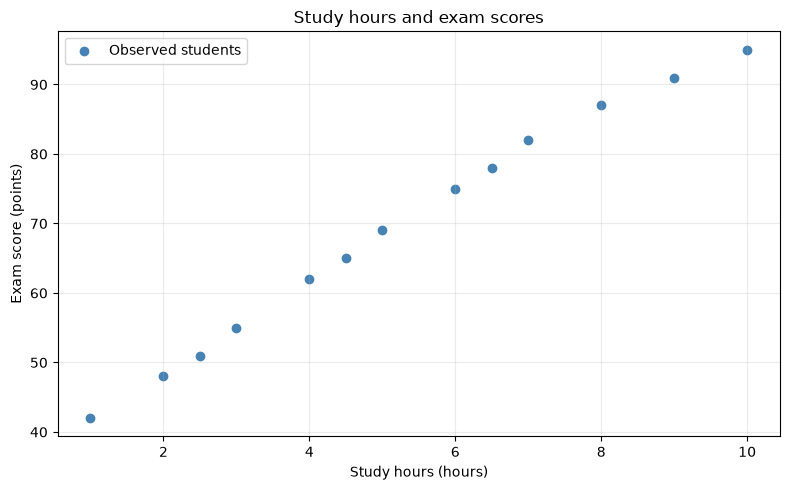

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["StudyHours"], df["ExamScore"], color="steelblue",
           label="Observed students")
ax.set_title("Study hours and exam scores")
ax.set_xlabel("Study hours (hours)")
ax.set_ylabel("Exam score (points)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


The plot shows a strong positive association: students who studied for more hours generally scored higher. The points follow a nearly straight pattern, although the increase appears to become slightly less steep at the highest study times. There are no obvious isolated or unusual points, but this small observational dataset cannot establish that study hours alone cause higher scores.

The fitted-line overlay is added to this figure after the model is trained in Stage 5, so the notebook can run from top to bottom without using an undefined model.


## 5. Linear Regression model

### Prepare the input and target

`X` contains only `StudyHours`, the input used to predict a score. `y` contains `ExamScore`, the target the model learns to estimate; `AboveAverage` is used only for descriptive analysis, not as a predictor.


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Double brackets preserve the two-dimensional feature table.
X = df[["StudyHours"]]
y = df["ExamScore"]

print("X shape (observations, features):", X.shape)
print("y shape (observations,):", y.shape)


X shape (observations, features): (13, 1)
y shape (observations,): (13,)


`X` has shape `(13, 1)`, meaning 13 observations and one input feature, while `y` has shape `(13,)`. The two-dimensional feature table is the format scikit-learn expects.


### Split the data into training and test sets


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))


Training observations: 10
Test observations: 3


There are 10 training observations and 3 test observations. The model learns only from the training set, while the held-out test set checks its predictions on observations it did not fit; `random_state=42` makes this split reproducible.


### Fit the model


In [13]:
model = LinearRegression()
model.fit(X_train, y_train)

coefficient = model.coef_[0]
intercept = model.intercept_
print(f"Learned coefficient: {coefficient:.4f} score points per study hour")
print(f"Learned intercept: {intercept:.4f} score points")
print(f"Fitted equation: predicted score = {intercept:.4f} + {coefficient:.4f} * study hours")


Learned coefficient: 6.0713 score points per study hour
Learned intercept: 37.2329 score points
Fitted equation: predicted score = 37.2329 + 6.0713 * study hours


`model.fit(X_train, y_train)` learns the slope and intercept that minimize the squared differences between training scores and the fitted line. The coefficient of about 6.07 means one additional study hour is associated with an increase of about 6.07 points in the model's predicted score. The intercept of about 37.23 is the line's prediction at zero hours, but zero is outside the observed 1–10 hour range, so it should not automatically be treated as a realistic student result.


### Predict the held-out scores


In [14]:
predictions = model.predict(X_test)

test_results = pd.DataFrame({
    "StudyHours": X_test["StudyHours"],
    "ActualScore": y_test,
    "PredictedScore": predictions
})
test_results.round(2)


,StudyHours,ActualScore,PredictedScore
11,9.0,91,91.87
9,7.0,82,79.73
0,1.0,42,43.30


`model.predict(X_test)` applies the learned line to the three held-out study-hour values and returns one estimated score per observation. The table keeps the original test-row order and pairs each estimate with its actual score; all three predictions are close to their actual values, with error quantified in Stage 6.


### Fitted regression line for Stage 4

Now that the model is trained, I add its predicted line to the original scatter plot. Sorting the hours ensures that the line is drawn from left to right.


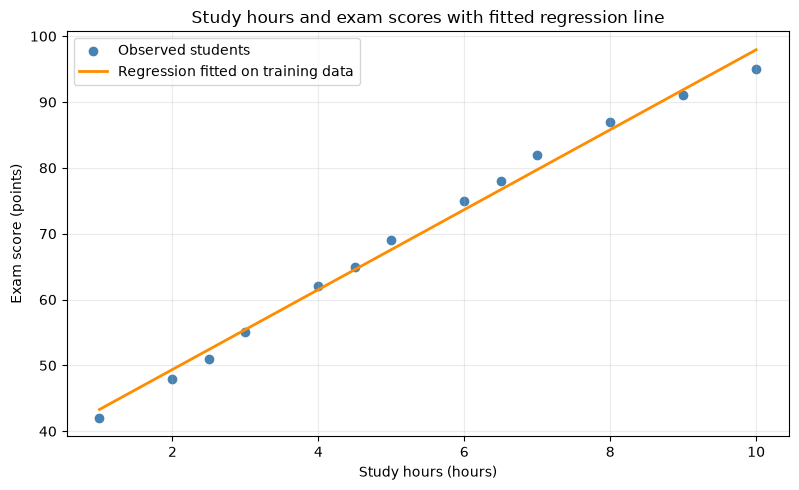

In [15]:
line_hours = X.sort_values("StudyHours")
line_predictions = model.predict(line_hours)

ax.plot(line_hours["StudyHours"], line_predictions, color="darkorange",
        linewidth=2, label="Regression fitted on training data")
ax.set_title("Study hours and exam scores with fitted regression line")
ax.legend()
display(fig)


The regression line summarizes the fitted relationship and provides an estimated score for a chosen study time, while the scatter points show individual observed scores. Vertical gaps between points and the line show prediction differences; the points lie fairly close to the line, although some curvature remains. All observations are shown for context, but the line was fitted using only the training observations.


## 6. Model evaluation and practical prediction

### Evaluate test predictions with MAE

Mean Absolute Error averages the absolute differences between the held-out actual scores and their predictions.


In [16]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, predictions)
print(f"Test Mean Absolute Error (MAE): {mae:.4f} exam-score points")


Test Mean Absolute Error (MAE): 1.4823 exam-score points


The test MAE is about **1.48 exam-score points**, meaning the model's predictions differ from the actual scores by 1.48 points on average across these three test observations. This is an error in score points, not a percentage or an accuracy rate, and it is not a guarantee about any individual prediction.


### Predict the score for 7.5 study hours


In [17]:
new_student = pd.DataFrame({"StudyHours": [7.5]})
predicted_score_7_5 = model.predict(new_student)[0]
print(f"Predicted exam score for 7.5 study hours: {predicted_score_7_5:.2f} points")


Predicted exam score for 7.5 study hours: 82.77 points


The predicted score is about **82.77 points**. Because 7.5 hours lies within the observed 1–10 hour range, this is interpolation-style use of the model; the estimate is still uncertain and should not be treated as a promised result.


### Consider the 100-hour boundary case


In [18]:
extreme_student = pd.DataFrame({"StudyHours": [100.0]})
predicted_score_100 = model.predict(extreme_student)[0]
print(f"Observed study-hour range: {study_hours.min():.1f}–{study_hours.max():.1f} hours")
print(f"Unreliable extrapolation at 100 hours: {predicted_score_100:.2f} points")


Observed study-hour range: 1.0–10.0 hours
Unreliable extrapolation at 100 hours: 644.36 points


I would not trust the 100-hour prediction. It extrapolates far beyond the observed 1–10 hour range and produces about 644.36 points, far beyond the observed scores of 42–95; the straight-line model has no built-in upper score limit. With only 13 observations and three held-out cases, the evaluation is a simple demonstration rather than strong evidence that the prototype will generalize to real students.


## 7. Final project conclusion and technical quality

### Final project conclusion

The supplied dataset shows a strong positive association between study hours and exam scores. Students who studied longer generally achieved higher scores, and the scatter plot follows a nearly linear pattern with no obvious isolated outliers. The Linear Regression line lies close to the observations, although the increase in scores becomes slightly less steep at the upper end. Its test MAE of approximately 1.48 exam-score points suggests a reasonable fit for this small demonstration.

For a student studying 7.5 hours, the trained model predicts approximately 82.77 points. This demonstrates how the prototype turns a study-time input into a numerical estimate within the observed range. It does not guarantee an individual student's result.

There are several limitations. The dataset contains only 13 observations, with just three in the test set, so the evaluation could change substantially with different students. Study hours are the only predictor, and an association does not show that additional study alone causes a higher score. The model also assumes a straight-line relationship and cannot justify extrapolation to 100 hours.

I recommend using the prototype for exploring the supplied data, while collecting a larger, more representative dataset before practical use. Future inputs could include attendance, prior grades, assignment performance, sleep and course difficulty, followed by evaluation on new students.


### Library understanding

| Library | Role in this project |
|---|---|
| NumPy | Stores the numerical arrays, calculates the summary statistics, and compares all scores with their mean using a vectorized Boolean operation. |
| Pandas | Builds a labelled DataFrame, displays and summarizes observations, creates the `AboveAverage` column, and filters rows for the stakeholder query. |
| Matplotlib | Draws the raw scatter plot and the line generated from the trained model's predictions. |
| scikit-learn | Separates training and test data, fits Linear Regression, generates predictions, and calculates test MAE. |

### Technical quality checks

The checks below confirm that the numerical arrays still match the DataFrame, the training and test rows are separate, and the above-average counts agree. These complement a fresh-kernel run of the complete notebook.


In [19]:
assert np.array_equal(df["StudyHours"].to_numpy(), study_hours)
assert np.array_equal(df["ExamScore"].to_numpy(), exam_scores)
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(df)
assert df["AboveAverage"].sum() == above_average_count
assert np.isclose(df["ExamScore"].std(), np.std(exam_scores, ddof=1))
print("Data consistency and train/test separation checks passed.")


Data consistency and train/test separation checks passed.


### Sources

The dataset and project requirements come from the supplied *Assignment 1 — Build a Student Exam Performance Predictor* brief. The [shared Data Science MBZUAI roadmap](https://github.com/amerbarhoush-dot/data-science-mbzuai) was used as supplementary guidance on reproducibility, held-out evaluation and communicating limitations.

Method details were checked against the official documentation: [NumPy standard deviation](https://numpy.org/doc/stable/reference/generated/numpy.std.html), [Pandas describe](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html), [Pandas standard deviation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.std.html), [Matplotlib scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) and [plot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html), [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html), [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html), and [MAE](https://scikit-learn.org/stable/modules/model_evaluation.html#mean-absolute-error).
